# 15 · Forces fluides et paradoxe de d'Alembert

*Notebook 15 du cours. Il suppose le notebook 14 (écoulement potentiel : vitesse et pression de Bernoulli).*

Le notebook 14 donne, pour une forme $\bar\rho$, le champ de vitesse et la pression autour d'elle. Pour optimiser, il faut un **nombre** : la force que le fluide exerce sur la pièce. Sous un rotor, c'est la composante verticale qui compte : le bras est dans le sillage descendant du rotor, et la force vers le bas sur le bras est de la **poussée perdue** (*download*).

Voici le piège, connu depuis 1752 : **dans un écoulement potentiel stationnaire, la force sur le corps est nulle.** Le modèle que l'on vient de valider ne peut donc pas, tel quel, donner une traînée. Le projet contourne cela avec un **indicateur de forme** (pression de Bernoulli au vent, pression de culot constante sous le vent). Ce notebook le construit, le met à l'épreuve, et mesure ce qu'il vaut. La conclusion est moins confortable que le plan ne le laissait supposer ; elle est chiffrée ci-dessous.

**Plan.**
1. De la pression à la force, sur la grille diffuse (avec une vérification exacte : Archimède) ;
2. Le paradoxe de d'Alembert, numériquement ; ce que vaut la force numérique ;
3. Pourquoi, en réalité, il y a une traînée ;
4. L'indicateur du projet $D$ et sa décomposition exacte ;
5. Le biais d'interface, et une correction ;
6. Ce que l'indicateur voit de la forme ;
7. Gradient et indicateur de blocage ;
8. Bilan.

**Code promu dans `src`.** `flow/aero.py` : `bernoulli_pressure`, `density_gradient`, `pressure_force`, `download_force`, `fluid_side_pressure` (nouvelle), `blockage` ; `objectives/aerodynamic.py::relative_download`. Contrats : C-CONV-07, C-AERO-01 à 05 (C-AERO-01 et 04 **réécrits** : voir §2 et §6).

In [1]:
import sys, math, time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))

from aeroptimizer.flow.aero import (blockage, density_gradient, download_force, fluid_side_pressure, pressure_force)
from aeroptimizer.flow.potential import PotentialFlow
from aeroptimizer.grid import Grid

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

RHO_AIR = 1.225
Q = 0.5 * RHO_AIR                              # pression dynamique pour U_ref = 1 : q = ½ ρ U²

def fraction(dedans, nx, nz, sub=8):
    # fraction d'aire de la forme {dedans(X, Z)} dans chaque cellule (suréchantillonnage sub×sub)
    o = (np.arange(sub) + 0.5) / sub
    X = np.arange(nx)[:, None, None, None] + o[None, None, :, None]
    Z = np.arange(nz)[None, :, None, None] + o[None, None, None, :]
    return torch.tensor(dedans(X, Z).mean(axis=(2, 3)))

def disque(R, nx, nz):
    return fraction(lambda X, Z: (X - nx / 2) ** 2 + (Z - nz / 2) ** 2 <= R * R, nx, nz)

def oeuf(R, nx, nz, avant=1.0, arriere=3.0):
    # deux demi-ellipses de demi-largeur R ; demi-axes selon z : `avant` R en amont (z > centre), `arriere` R en aval
    cx, cz = nx / 2, nz / 2
    return fraction(lambda X, Z: ((X - cx) / R) ** 2 + ((Z - cz) / (R * np.where(Z >= cz, avant, arriere))) ** 2 <= 1, nx, nz)

def coin(R, nx, nz, pointe_en_haut=True):
    # triangle isocèle (angle au sommet ≈ 53°), base de largeur 4R, hauteur 4R : un corps à arêtes vives, dissymétrique
    cx, cz = nx / 2, nz / 2
    if pointe_en_haut:
        return fraction(lambda X, Z: (abs(X - cx) <= (cz + 2 * R - Z) * 0.5) & (Z <= cz + 2 * R) & (Z >= cz - 2 * R), nx, nz)
    return fraction(lambda X, Z: (abs(X - cx) <= (Z - (cz - 2 * R)) * 0.5) & (Z <= cz + 2 * R) & (Z >= cz - 2 * R), nx, nz)

def plaque(R, nx, nz):
    # plaque mince perpendiculaire à l'écoulement, largeur 2R, épaisseur 2 max(1, R/8)
    t = max(1.0, R / 8)
    return fraction(lambda X, Z: (abs(X - nx / 2) <= R) & (abs(Z - nz / 2) <= t), nx, nz)

def largeur_frontale(rho, h=(1.0, 1.0)):
    # A = somme des −min(∂z ρ, 0) h_x : la largeur du corps vue par l'écoulement (m)
    return float(-torch.clamp(density_gradient(rho, h)[..., -1], max=0.0).sum() * h[0])

def veine(R, facteur_l=16, facteur_h=24, U=1.0):
    nx, nz = facteur_l * R, facteur_h * R
    return nx, nz, PotentialFlow(Grid((nx, nz), (1.0, 1.0)), torch.full((nx,), U), n_pad=4, rho_air=RHO_AIR)

## 1. De la pression à la force, sur une grille diffuse

La force du fluide sur un corps $\Omega_s$ est l'intégrale de la pression sur sa surface : $\mathbf F=-\oint_{\partial\Omega_s}p\,\mathbf n\,dS$, avec $\mathbf n$ la normale sortante du corps (la pression pousse vers l'intérieur). Sur une grille, on n'a pas de surface explicite, seulement la densité $\bar\rho$ ($1$ dans le corps, $0$ dehors). Or le gradient de l'indicatrice du corps est $\nabla\bar\rho=-\mathbf n\,\delta_{\partial\Omega_s}$ : une mesure portée par la surface, dirigée vers l'intérieur. D'où l'identité

$$
\mathbf F=\int_\Omega p\,\nabla\bar\rho\;d\Omega\ \approx\ h^d\sum_e p_e\,(\nabla\bar\rho)_e ,
$$

une somme sur les éléments, **entièrement vectorisable et différentiable** (le gradient de $\bar\rho$ est une différence finie centrée). Aucun contour à extraire ni à trianguler.

**Vérification exacte : Archimède.** Dans un fluide au repos, $p=-\rho_fgz$ (la pression croît en descendant). Un corps immergé subit la poussée $\mathbf F=+\rho_fgV\,\mathbf e_z$. L'identité ci-dessus, avec la somme discrète, doit le retrouver.

In [2]:
nx, nz = 64, 80; rho = disque(10, nx, nz)
z = (torch.arange(nz) + 0.5)[None, :].expand(nx, nz)
p_hydro = -9.81 * z                                                    # ρ_f g = 9,81
F = pressure_force(rho, p_hydro, (1.0, 1.0))
print(f"F = {F.numpy()}   (Fx, Fz) ;  Archimède : ρ_f g V = 9,81 × {float(rho.sum()):.4f} = {9.81*float(rho.sum()):.4f}")
print(f"écart relatif sur F_z : {abs(float(F[1]) - 9.81*float(rho.sum()))/(9.81*float(rho.sum())):.1e}")

F = [   0.     3082.1794]   (Fx, Fz) ;  Archimède : ρ_f g V = 9,81 × 314.1875 = 3082.1794
écart relatif sur F_z : 0.0e+00


Exact à la précision machine : la pression hydrostatique est linéaire, la différence centrée est exacte sur une fonction linéaire, et le télescopage de la somme redonne le volume. La formule discrète ne contient donc **aucune erreur propre** ; toute erreur sur la force viendra de la **pression** qu'on lui donne (le champ éléments finis du notebook 14), pas de l'intégration.

## 2. Le paradoxe de d'Alembert, numériquement

**Énoncé.** Un corps immobile dans un écoulement **potentiel, stationnaire, incompressible, sans circulation**, ne subit **aucune force** : ni traînée (dans le sens de l'écoulement), ni portance. Esquisse de la preuve : la force est la variation de quantité de mouvement du fluide entre l'amont et l'aval ; en potentiel, l'écoulement aval est le miroir de l'amont (la pression remonte derrière le corps exactement comme elle est montée devant), donc rien n'est perdu.

Sur le cylindre, la pression $C_p=1-4\sin^2\theta$ est **symétrique avant/arrière** : la surpression à l'amont est compensée par la surpression à l'aval (le point d'arrêt arrière, $C_p=1$), et les dépressions des épaules sont latérales. Vérifions avec la formule du §1 sur une grille.

In [3]:
print(f"{'forme':<26} {'R':>3} {'F_z / (q A)':>12} {'F_x / (q A)':>12}   (A = largeur frontale ; q = ½ρU²)")
for nom, f in [("cylindre", lambda R, nx, nz: disque(R, nx, nz)), ("plaque mince ⟂ écoulement", plaque)]:
    for R in (8, 16, 32):
        nx, nz, pf = veine(R); rho = f(R, nx, nz); st = pf.solve(rho); A = largeur_frontale(rho)
        F = pressure_force(rho, st.p_rel, (1.0, 1.0))
        print(f"{nom:<26} {R:>3d} {float(F[1])/Q/A:>12.4f} {float(F[0])/Q/A:>12.4f}")

forme                        R  F_z / (q A)  F_x / (q A)   (A = largeur frontale ; q = ½ρU²)
cylindre                     8       0.0001      -0.0000


cylindre                    16       0.0001      -0.0000


cylindre                    32       0.0001       0.0000
plaque mince ⟂ écoulement    8       0.0000      -0.0000


plaque mince ⟂ écoulement   16       0.0000      -0.0000


plaque mince ⟂ écoulement   32       0.0000       0.0000


La force est nulle à $10^{-4}$ près (en unités de $qA$) : d'Alembert est retrouvé. **Mais ce n'est pas une preuve que la force numérique est exacte** : le cylindre et la plaque sont symétriques avant/arrière, donc les erreurs de l'interface (côté vent et côté sous le vent) s'annulent **par symétrie**, quelle que soit leur taille. Le bon test est un corps **dissymétrique**, pour lequel la force exacte est encore nulle mais où rien ne s'annule gratuitement :
- un **œuf** lisse : demi-ellipse courte en amont, longue en aval ;
- un **coin** (triangle) à arêtes vives.

Pour chacun, $F_z/(qA)$ devrait être nul. La dernière colonne applique la correction `fluid_side_pressure` du §5 (la pression est prélevée côté fluide) ; ignorez-la pour l'instant.

In [4]:
print(f"{'forme':<22} {'R':>3} {'F_z / (qA) brut':>16} {'F_z / (qA) côté fluide':>24}")
for nom, f in [("œuf (avant 1R, arrière 3R)", lambda R, nx, nz: oeuf(R, nx, nz, 1.0, 3.0)), ("œuf inversé", lambda R, nx, nz: oeuf(R, nx, nz, 3.0, 1.0)),
               ("coin, pointe en haut", coin), ("coin, pointe en bas", lambda R, nx, nz: coin(R, nx, nz, False))]:
    for R in (8, 16, 32):
        nx, nz, pf = veine(R); rho = f(R, nx, nz); st = pf.solve(rho); A = largeur_frontale(rho)
        brut = pressure_force(rho, st.p_rel, (1.0, 1.0))[1]
        cote = pressure_force(rho, fluid_side_pressure(st.p_rel, rho), (1.0, 1.0))[1]
        print(f"{nom:<22} {R:>3d} {float(brut)/Q/A:>16.3f} {float(cote)/Q/A:>24.3f}")

forme                    R  F_z / (qA) brut   F_z / (qA) côté fluide
œuf (avant 1R, arrière 3R)   8            0.187                   -0.056


œuf (avant 1R, arrière 3R)  16            0.060                   -0.029


œuf (avant 1R, arrière 3R)  32            0.109                   -0.015
œuf inversé              8           -0.187                    0.056


œuf inversé             16           -0.059                    0.030


œuf inversé             32           -0.109                    0.016
coin, pointe en haut     8          -10.820                    0.688


coin, pointe en haut    16          -11.585                    0.628


coin, pointe en haut    32          -12.213                    0.557
coin, pointe en bas      8           10.827                   -0.688


coin, pointe en bas     16           11.592                   -0.628


coin, pointe en bas     32           12.220                   -0.556


**Lecture : c'est le plancher de bruit de l'indicateur.**
- Pour l'œuf lisse, la force brute vaut $0{,}06$ à $0{,}19\,qA$ au lieu de $0$, **sans tendance claire** avec le raffinement ($0{,}19$, $0{,}06$, $0{,}11$). L'œuf inversé donne l'opposé exact (la formule est antisymétrique).
- Pour le coin, c'est franchement mauvais : $-10{,}8$, $-11{,}6$, $-12{,}2\,qA$, et la valeur **grossit** avec le raffinement. Les arêtes vives font diverger la vitesse potentielle ($C_p\to-\infty$ au coin), et la couche d'interface y pèse énormément.
- Le prélèvement de la pression côté fluide (§5) ramène le coin de $-12$ à $+0{,}6\,qA$ environ et l'œuf à $-0{,}06$ à $-0{,}02\,qA$ : c'est mieux d'un ordre de grandeur pour le coin, mais pas nul.

**Conséquence.** La force « d'Alembert » calculée sur la grille n'est exacte qu'à quelques dixièmes de $qA$ près pour des formes lisses, et pas du tout pour des arêtes vives. Toute **différence de $D$ entre deux designs inférieure à $\sim0{,}1\,qA$ est dans le bruit** de la méthode. On garde ce chiffre en tête pour juger de l'indicateur du §4.

## 3. Pourquoi, en réalité, il y a une traînée

Les hypothèses de d'Alembert sont fausses dans un fluide réel :

1. **La viscosité** crée une **couche limite** le long de la paroi. À l'arrière d'un corps épais, le gradient de pression est défavorable (la pression remonte) ; la couche limite, qui a perdu de l'énergie par frottement, ne peut pas remonter ce gradient et **se détache**.
2. Derrière le point de décollement s'ouvre un **sillage** : une zone de recirculation, à basse pression et pleine de tourbillons. La pression arrière ne remonte pas jusqu'au niveau de l'amont (**pression de culot** $p_b<p_\infty$) : le bilan avant/arrière n'est plus nul, c'est la **traînée de pression**.
3. Le sillage emporte une quantité de mouvement qui manque à l'écoulement : le bilan de quantité de mouvement de la preuve de d'Alembert est alors faux.

**Où est-on pour un bras de drone ?** Le nombre de Reynolds $Re=U\,w/\nu$ vaut, pour $U\approx5$–$10\,$m/s, $w\approx1\,$cm et $\nu\approx1{,}5\times10^{-5}\,\mathrm{m^2/s}$ : $Re\approx3\times10^3$ à $7\times10^3$. À ces valeurs, un corps épais (bras à section carrée ou ronde) a un **sillage décollé**, et la traînée est essentiellement de **pression**. La viscosité est faible mais son rôle est décisif.

**Ordres de grandeur du coefficient de traînée** $C_d=F/(\tfrac12\rho U^2A)$, **de mémoire, à vérifier avant tout usage** : cylindre circulaire $\approx1{,}0$ à $1{,}2$ pour $Re$ de $10^3$ à $10^5$ ; plaque mince normale à l'écoulement $\approx1{,}9$ à $2$ ; corps profilé (profil allongé) bien inférieur à $0{,}1$ ; potentiel : $0$. Voilà ce que Laplace ne voit pas. Pour avoir ces effets avec un modèle fluide, il faut de la viscosité : c'est le plan B (pénalisation de Brinkman et équations de Stokes, leçon 16, optionnelle).

## 4. L'indicateur du projet $D$ et sa décomposition exacte

On **remplace** la pression sous le vent par une constante, la pression de culot $p_b-p_\infty=-\tfrac12\rho_aU_{\rm ref}^2\,c_b$, et on garde la pression de Bernoulli au vent. Avec l'axe $z$ vers le haut et l'écoulement descendant, un élément au vent a $\partial_z\bar\rho<0$ (de moins en moins de solide en montant) et un élément sous le vent a $\partial_z\bar\rho>0$ :

$$
D=-F_z\approx-\sum_e h^d\Big[(p-p_\infty)_e\,\min(\partial_z\bar\rho_e,0)+(p_b-p_\infty)\,\max(\partial_z\bar\rho_e,0)\Big],\qquad D>0\iff\text{force vers le bas}.
$$

**Une identité qui change la lecture.** Sur une colonne verticale qui traverse le corps, $\bar\rho$ monte de $0$ à $1$ puis redescend : la somme de $\partial_z\bar\rho$ sur la colonne est nulle, et donc la somme de sa **partie positive** vaut exactement $1$ (le saut total à la face sous le vent), comme celle de la partie négative vaut $-1$. Les deux termes s'intègrent en largeur frontale $A$ :

$$
\underbrace{\sum_e h^d\max(\partial_z\bar\rho_e,0)}_{A_{\rm aval}}=\underbrace{-\sum_e h^d\min(\partial_z\bar\rho_e,0)}_{A_{\rm amont}}=A,
\qquad\boxed{\,D=\tfrac12\rho_aU_{\rm ref}^2\,A\,\big(c_b+\langle C_p\rangle_{\rm amont}\big)\,}
$$

où $\langle C_p\rangle_{\rm amont}$ est le $C_p$ moyen sur la largeur frontale, côté au vent. **Le terme de culot ne dépend de la forme que par la largeur frontale** $A$ : un corps à l'arrière arrondi et un corps à l'arrière effilé de même largeur ont le même terme de culot. Vérifions l'identité, puis la valeur de $\langle C_p\rangle_{\rm amont}$ pour le cylindre.

In [5]:
kw = dict(h=(1.0, 1.0), rho_air=RHO_AIR, u_ref=1.0)
print("A_amont = A_aval (à la précision machine) ?")
for nom, f in [("cylindre R=8", lambda nx, nz: disque(8, nx, nz)), ("œuf 1R/3R", lambda nx, nz: oeuf(8, nx, nz, 1.0, 3.0)), ("plaque R=8", lambda nx, nz: plaque(8, nx, nz)), ("coin", lambda nx, nz: coin(8, nx, nz))]:
    rho = f(128, 192); dz = density_gradient(rho, (1.0, 1.0))[..., 1]
    print(f"  {nom:<14} A_amont = {float(-torch.clamp(dz, max=0).sum()):>9.4f}   A_aval = {float(torch.clamp(dz, min=0).sum()):>9.4f}")

nx, nz, pf = veine(16); rho = disque(16, nx, nz); st = pf.solve(rho); A = largeur_frontale(rho)
D0 = float(download_force(rho, st.p_rel, c_b=0.0, **kw)); D1 = float(download_force(rho, st.p_rel, c_b=1.0, **kw))
print(f"\ncylindre R=16 (A = {A:.1f}) : D(c_b=0) / (qA) = {D0/Q/A:.3f} = <C_p>_amont ; D(c_b=1) − D(c_b=0) = {(D1-D0)/Q/A:.6f} q A  (pente en c_b : q A)")
print(f"valeur analytique de <C_p>_amont pour le cylindre : ∫(1 − 4 sin²θ) cosθ dθ / ∫ cosθ dθ = −1/3 = {-1/3:.3f}")
print(f"→ D > 0 exige c_b > −<C_p>_amont : {-D0/Q/A:.2f} (numérique)  contre  {1/3:.2f} (analytique)")

A_amont = A_aval (à la précision machine) ?
  cylindre R=8   A_amont =   16.0000   A_aval =   16.0000
  œuf 1R/3R      A_amont =   16.0000   A_aval =   16.0000
  plaque R=8     A_amont =   16.0000   A_aval =   16.0000
  coin           A_amont =   31.0000   A_aval =   31.0000



cylindre R=16 (A = 32.0) : D(c_b=0) / (qA) = -0.722 = <C_p>_amont ; D(c_b=1) − D(c_b=0) = 1.000000 q A  (pente en c_b : q A)
valeur analytique de <C_p>_amont pour le cylindre : ∫(1 − 4 sin²θ) cosθ dθ / ∫ cosθ dθ = −1/3 = -0.333
→ D > 0 exige c_b > −<C_p>_amont : 0.72 (numérique)  contre  0.33 (analytique)


Deux choses.

**(i)** L'identité $D=qA(c_b+\langle C_p\rangle_{\rm amont})$ est vérifiée ($A_{\rm amont}=A_{\rm aval}$ pour toutes les formes testées, y compris le coin et la plaque, et la pente en $c_b$ vaut exactement $qA$).

**(ii)** **$\langle C_p\rangle_{\rm amont}$ est négatif** : $-1/3$ en théorie (potentiel pur) pour le cylindre, parce que les épaules en dépression, larges, pèsent plus que le seul point d'arrêt en surpression. Pour que $D$ soit **positif**, il faut un coefficient de culot $c_b>1/3$ dans la théorie. **Le projet fixe $c_b\approx0{,}2$ à $0{,}5$** ⚠ (FORMALISM §4.6) : à $c_b=0{,}3$, $D$ est **nul à négatif** pour un cylindre. Le contrat C-AERO-01 original (« avec $c_b>0$, $D>0$ ») est **faux** tel qu'il est écrit, et je l'ai réécrit.

Et le chiffre numérique brut ($-0{,}72$ au lieu de $-0{,}33$) est encore plus loin de la théorie : ce qui nous amène au biais d'interface.

## 5. Le biais d'interface, et une correction

La somme de $D$ pèse chaque élément par $|\partial_z\bar\rho|$ : **seules les cellules de l'interface comptent**. Or c'est exactement là que la vitesse éléments finis est la moins fiable (notebook 14 : l'erreur sur la couche d'une cellule contre le corps est de $5$ à $6\,\%$ sur $|\mathbf v|$, et le $C_p$ à moins de deux cellules est en dents de scie). Où sont les poids, et quel $C_p$ y trouve-t-on ? On sépare les cellules de l'interface selon leur densité, pour le cylindre $R=16$.

In [6]:
nx, nz, pf = veine(16); rho = disque(16, nx, nz); st = pf.solve(rho)
dz = density_gradient(rho, (1.0, 1.0))[..., 1]; w = -torch.clamp(dz, max=0.0); A = float(w.sum())
cp = (st.p_rel.reshape(nx, nz)) / Q
X, Z = np.meshgrid(np.arange(nx) + .5, np.arange(nz) + .5, indexing="ij")
r = np.maximum(np.hypot(X - nx / 2, Z - nz / 2), 16); a = np.arctan2(np.abs(X - nx / 2), np.abs(Z - nz / 2)); s = 256 / r**2
cp_exact = torch.tensor(1 - (1 + s**2 - 2 * s * np.cos(2 * a)))          # C_p de la formule analytique, mêmes poids
print(f"<C_p>_amont : numérique {float((w*cp).sum()/A):.3f} ; formule analytique avec les mêmes poids {float((w*cp_exact).sum()/A):.3f}")
vit = st.v.pow(2).sum(-1).sqrt().reshape(nx, nz)
print(f"vitesse maximale dans une cellule entièrement solide (rho = 1) : {float(vit[rho > 1 - 1e-9].max()):.2f} U ; maximale de la solution analytique (épaule) : 2 U\n")
print(f"{'cellules de densité':>22} {'part du poids':>14} {'C_p moyen numérique':>20}")
for lo, hi, nom in [(0, 1e-9, "= 0 (fluide pur)"), (1e-9, 0.5, "0 < rho < 0,5"), (0.5, 1 - 1e-9, "0,5 ≤ rho < 1"), (1 - 1e-9, 1.1, "= 1 (solide pur)")]:
    m = (rho <= hi) if lo == 0 else ((rho >= lo) & (rho < hi))
    ws = float(w[m].sum()); print(f"{nom:>22} {ws/A:>14.3f} {float((w*cp)[m].sum()/ws) if ws > 0 else float('nan'):>20.3f}")

<C_p>_amont : numérique -0.722 ; formule analytique avec les mêmes poids -0.309
vitesse maximale dans une cellule entièrement solide (rho = 1) : 3.17 U ; maximale de la solution analytique (épaule) : 2 U

   cellules de densité  part du poids  C_p moyen numérique
      = 0 (fluide pur)          0.182                0.492
         0 < rho < 0,5          0.266               -0.656
         0,5 ≤ rho < 1          0.433               -1.103
      = 1 (solide pur)          0.120               -1.334


**Le diagnostic est net.** Avec les **mêmes poids**, la formule analytique donne $-0{,}31$ (proche du $-1/3$ théorique) et la pression éléments finis donne $-0{,}72$. Plus de la moitié du poids ($55\,\%$) est portée par des cellules **à moitié ou entièrement solides**, où le $C_p$ numérique vaut $-1{,}1$ à $-1{,}3$ : dans ces cellules, qui partagent leurs nœuds avec le fluide, la vitesse $\nabla\varphi$ est **surestimée** (on mesure jusqu'à $3{,}2\,U$ dans une cellule entièrement solide, contre $2\,U$ au maximum de l'épaule analytique) et la pression est trop basse. Le FORMALISM (§4.6) annonçait l'inverse (« vitesse amortie, pression surestimée ») : **ce n'est pas ce que l'on mesure ici** (interface en fractions d'aire, $q=3$, cylindre 2D) : le biais est dans l'autre sens, et il domine le résultat. Le sens du biais pourrait dépendre de $q$ et du lissage de $\bar\rho$ ; il n'a pas été exploré.

**Une correction simple : prélever la pression côté fluide.** `fluid_side_pressure(p, rho_bar, m=2, k=1)` remplace $p_e$ par la moyenne de $p$ sur les $3\times3$ voisins, pondérée par $(1-\bar\rho)^m$ : les cellules solides ne comptent presque plus (et, avec un petit $\varepsilon=10^{-2}$ au dénominateur, l'estimation tend vers $0$ là où il n'y a pas de fluide du tout, au lieu de moyenner des valeurs aberrantes). C'est dérivable, et son effet se mesure sur $\langle C_p\rangle_{\rm amont}$ :

In [7]:
print(f"{'forme':<14} {'R':>3} {'<Cp> brut':>10} {'côté fluide':>12}     (cylindre : théorie −0,333)")
for nom, f in [("cylindre", disque), ("œuf 1R/3R", lambda R, nx, nz: oeuf(R, nx, nz, 1.0, 3.0)), ("plaque", plaque), ("coin", coin)]:
    for R in (8, 16, 32):
        nx, nz, pf = veine(R); rho = f(R, nx, nz); st = pf.solve(rho)
        w = -torch.clamp(density_gradient(rho, (1.0, 1.0))[..., 1], max=0.0)
        moy = lambda pp: float((w * pp.reshape(nx, nz)).sum() / w.sum()) / Q
        print(f"{nom:<14} {R:>3d} {moy(st.p_rel):>10.3f} {moy(fluid_side_pressure(st.p_rel, rho)):>12.3f}")

forme            R  <Cp> brut  côté fluide     (cylindre : théorie −0,333)
cylindre         8     -0.919       -0.254


cylindre        16     -0.722       -0.291


cylindre        32     -0.778       -0.313
œuf 1R/3R        8     -0.680       -0.139


œuf 1R/3R       16     -0.529       -0.170


œuf 1R/3R       32     -0.573       -0.189
plaque           8    -34.815       -0.036


plaque          16    -36.273       -0.065


plaque          32    -37.222       -0.148
coin             8     -1.177       -0.688


coin            16     -1.331       -0.783


coin            32     -1.466       -0.870


**Lecture.**
- **Cylindre** : de $-0{,}72$ / $-0{,}78$ à $-0{,}29$ / $-0{,}31$ pour $R=16$, $32$, près du $-1/3$ théorique (l'écart restant est le blocage de la veine, le même effet qu'au notebook 14).
- **Plaque mince** : le $\langle C_p\rangle_{\rm amont}$ brut vaut $-35$ à $-37$ : un chiffre **aberrant**, produit par les cellules d'arête où la vitesse potentielle diverge. Côté fluide : $-0{,}03$ à $-0{,}15$, valeurs raisonnables mais **qui dérivent avec le raffinement** (la singularité d'arête, intégrable, converge lentement).
- **Coin** : aucune des deux estimations n'est fiable (arêtes vives, singularités), même si la correction ramène la force de d'Alembert à $\approx0{,}6\,qA$.

**Ce qu'il faut retenir : la correction est un pansement, pas une validation.** Elle est choisie ici parce qu'elle ramène le cylindre à la théorie et la plaque à des valeurs physiques ; ses paramètres $(m,k)=(2,1)$ n'ont pas été optimisés. Elle **n'est pas dans le modèle du projet** (FORMALISM) : c'est à vous de décider de l'y mettre. Les deux versions (brute et côté fluide) sont dérivables ; le contrat C-AERO-05 vérifie les deux.

## 6. Ce que l'indicateur voit de la forme

Le but de $D$ est de **récompenser les formes qui perdent peu de poussée**. Comparons des corps de même largeur frontale et de même face au vent, dont seule la **forme de l'arrière** change : arrière arrondi, puis de plus en plus effilé (œuf avec arrière de $1$, $2$, $3$, $5$ rayons).

In [8]:
nx, nz, pf = veine(10, 16, 24); zero = torch.zeros(nx, nz)
print(f"{'arrière':>8} {'A':>6} {'D culot seul (p=0) / (qA c_b)':>30} {'D(c_b=0)/(qA)':>15} {'D(c_b=0,4)/(qA)':>17} {'C_eff/ref − 1':>14}")
ref = float(blockage(pf.solve(torch.zeros(nx, nz)).phi, pf.b, nz * 1.0))
for arriere in (1.0, 2.0, 3.0, 5.0):
    rho = oeuf(10, nx, nz, 1.0, arriere); st = pf.solve(rho); A = largeur_frontale(rho)
    d_culot = float(download_force(rho, zero, c_b=1.0, **kw)) / Q / A                         # pression nulle : reste le seul terme de culot
    d0 = float(download_force(rho, st.p_rel, c_b=0.0, **kw)) / Q / A
    d4 = float(download_force(rho, st.p_rel, c_b=0.4, **kw)) / Q / A
    ceff = float(blockage(st.phi, pf.b, nz * 1.0)) / ref - 1
    print(f"{arriere:>7.0f}R {A:>6.2f} {d_culot:>30.6f} {d0:>15.3f} {d4:>17.3f} {ceff:>14.3f}")

 arrière      A  D culot seul (p=0) / (qA c_b)   D(c_b=0)/(qA)   D(c_b=0,4)/(qA)  C_eff/ref − 1
      1R  20.00                       1.000000          -0.829            -0.429          0.017


      2R  20.00                       1.000000          -0.679            -0.279          0.022
      3R  20.00                       1.000000          -0.612            -0.212          0.026
      5R  20.00                       1.000000          -0.549            -0.149          0.035


**Lecture.**
- **Le terme de culot est identique pour toutes les formes arrière** (colonne 3 : exactement $c_b=1$ en unités de $qA$ ; ligne identique à la sixième décimale) : c'est l'identité du §4. Un $c_b$ **constant** ne peut pas récompenser un carénage de l'arrière, ce que le FORMALISM (§4.6, dernière puce) et le contrat C-AERO-04 original affirmaient (« un design caréné voit la contribution de culot diminuer »). **Ce n'est pas le cas.**
- **Le seul effet de l'arrière passe par la pression au vent** : un arrière plus long change le champ de vitesse autour de tout le corps, et $\langle C_p\rangle_{\rm amont}$ passe de $-0{,}83$ à $-0{,}55$ quand l'arrière va de $1R$ à $5R$ (colonne 4). C'est un effet physique plausible (un corps plus allongé accélère moins le fluide), mais **petit** : $0{,}28\,qA$, de l'ordre du plancher de bruit du §2 ($\sim0{,}1\,qA$), contre un effet de $c_b$ de $0{,}4\,qA$.
- **La dernière colonne (indicateur de blocage)** : l'énergie cinétique en excès, mesurée par $C_{\rm eff}=\mathbf b^\top\boldsymbol\varphi/\delta\varphi$ (qui vaut $UW$ sans obstacle), **augmente** avec l'allongement ($1{,}7\,\%$ à $3{,}5\,\%$ de l'énergie sans obstacle) : elle pénalise la **longueur** de la contraction de la veine, pas le manque de profilage. Ce n'est donc pas non plus un indicateur de carénage ; il mesure l'obstruction.

**Ce que $D$ récompense donc**, à $c_b$ constant : **réduire la largeur frontale $A$** (premier effet, évident) et, faiblement, avoir une face au vent peu en dépression. **Il ne distingue pas un arrière effilé d'un arrière arrondi.** Pour le bras de drone, cela veut dire que l'optimisation poussera à affiner la section et ne trouvera pas de profil caréné à section donnée. Quelques pistes, **non testées** : un $c_b$ qui dépend de la pente locale de la face arrière (pente faible → recollement → culot moindre) ; ou passer au modèle de Brinkman–Stokes du plan B (leçon 16), où le décollement est calculé.

In [9]:
# Ce qu'est D en unités physiques, pour un exemple : un cylindre de 1 cm de diamètre, de 10 cm de long, dans un jet de 10 m/s
U, d_m, L_m = 10.0, 0.01, 0.10
q_phys = 0.5 * RHO_AIR * U**2
print(f"q = ½ρU² = {q_phys:.1f} Pa ; A = d × L = {d_m*L_m*1e4:.1f} cm² ; q A = {q_phys*d_m*L_m*1e3:.2f} mN")
nx, nz, pf = veine(16); rho = disque(16, nx, nz); st = pf.solve(rho); A = largeur_frontale(rho)
p_fluide = fluid_side_pressure(st.p_rel, rho)
print(f"{'c_b':>5} {'D/(qA) brut':>12} {'D brut (mN)':>12} {'D/(qA) côté fluide':>19} {'D côté fluide (mN)':>19}")
for c_b in (0.2, 0.3, 0.5, 1.0, 1.4):
    d1 = float(download_force(rho, st.p_rel, c_b=c_b, **kw)) / Q / A; d2 = float(download_force(rho, p_fluide, c_b=c_b, **kw)) / Q / A
    print(f"{c_b:>5.1f} {d1:>12.3f} {d1*q_phys*d_m*L_m*1e3:>12.2f} {d2:>19.3f} {d2*q_phys*d_m*L_m*1e3:>19.2f}")
w = -torch.clamp(density_gradient(rho, (1.0, 1.0))[..., 1], max=0.0)
cp_b, cp_f = [float((w * pp.reshape(nx, nz)).sum() / w.sum()) / Q for pp in (st.p_rel, p_fluide)]
print(f"\nPour reproduire un C_d de 1,1 (valeur de mémoire du cylindre), il faut c_b = C_d − <C_p>_amont = {1.1 - cp_b:.2f} (pression brute) ou {1.1 - cp_f:.2f} (côté fluide),")
print("contre 0,2 à 0,5 dans le FORMALISM : soit 3 à 4 fois la borne haute de la plage.")

q = ½ρU² = 61.3 Pa ; A = d × L = 10.0 cm² ; q A = 61.25 mN


  c_b  D/(qA) brut  D brut (mN)  D/(qA) côté fluide  D côté fluide (mN)
  0.2       -0.522       -31.99              -0.091               -5.60
  0.3       -0.422       -25.87               0.009                0.53
  0.5       -0.222       -13.62               0.209               12.78
  1.0        0.278        17.01               0.709               43.40
  1.4        0.678        41.51               1.109               67.90

Pour reproduire un C_d de 1,1 (valeur de mémoire du cylindre), il faut c_b = C_d − <C_p>_amont = 1.82 (pression brute) ou 1.39 (côté fluide),
contre 0,2 à 0,5 dans le FORMALISM : soit 3 à 4 fois la borne haute de la plage.


## 7. Gradient : où l'optimiseur pousse-t-il ?

$D$ est dérivable en $\bar\rho$ par **deux chemins** : directement par $\nabla\bar\rho$ dans la somme, et indirectement par la vitesse (la matrice dépend de $\bar\rho$, donc $\varphi$, donc $p$). Le second passe par l'état adjoint du notebook 7 sans code supplémentaire. Le contrat C-AERO-05 le vérifie par `gradcheck`. Voici la carte de $\partial D/\partial\bar\rho_e$ pour un cylindre ($c_b=0{,}4$) : une valeur **positive** là où ajouter de la matière augmente $D$ (donc où l'optimiseur en retirera).

pression brute  : D/q = -8.973 ; |dD/drho|/q max = 3.38 ; somme = -194.879
côté fluide     : D/q = 1.910 ; |dD/drho|/q max = 1.62 ; somme = -119.416


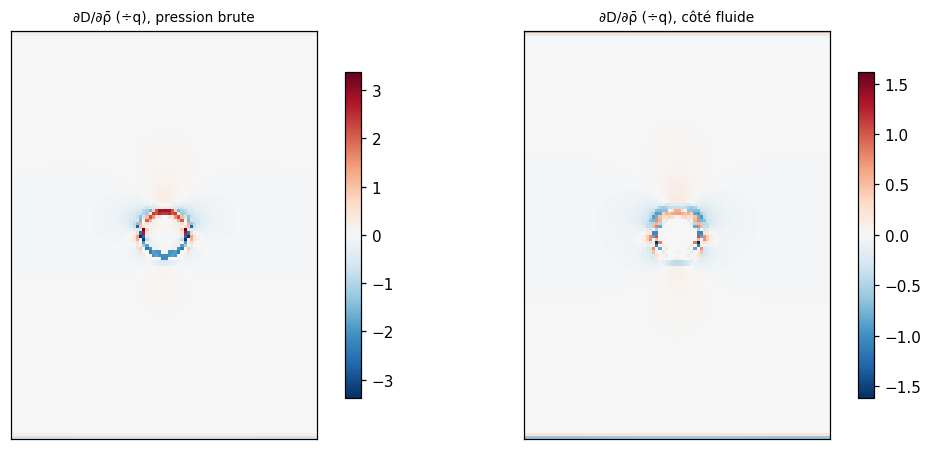

In [10]:
R = 8; nx, nz, pf = veine(R, 12, 16)
cartes = {}
for nom, cote in [("pression brute", False), ("côté fluide", True)]:
    rho = disque(R, nx, nz).clone().requires_grad_(True)
    p = pf.solve(rho).p_rel
    if cote: p = fluid_side_pressure(p, rho)
    D = download_force(rho, p, h=(1.0, 1.0), rho_air=RHO_AIR, u_ref=1.0, c_b=0.4); D.backward()
    cartes[nom] = rho.grad.numpy() / Q
    print(f"{nom:<15} : D/q = {float(D.detach())/Q:.3f} ; |dD/drho|/q max = {np.abs(cartes[nom]).max():.2f} ; somme = {cartes[nom].sum():.3f}")
fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (nom, c) in zip(axs, cartes.items()):
    m = np.abs(c).max(); im = ax.imshow(c.T, origin="lower", cmap="RdBu_r", vmin=-m, vmax=m); plt.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(f"∂D/∂ρ̄ (÷q), {nom}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Ce que montre la carte.** La sensibilité est **portée par la seule couche d'interface** (le champ lointain est à zéro à l'échelle de la figure), avec des signes opposés sur la face au vent (positif) et sous le vent (négatif). La version brute est plus irrégulière sur les flancs (extrêmes $\pm3{,}4$ contre $\pm1{,}6$ côté fluide). Les valeurs de $D/q$ elles-mêmes diffèrent beaucoup entre les deux versions ($-9{,}0$ contre $+1{,}9$ pour ce cylindre à $c_b=0{,}4$) : c'est le biais du §5. On n'a pas analysé plus loin la signification de cette carte pour le design. **Un optimiseur suivra ce gradient quel que soit son défaut** : si $D$ est biaisé, le design le sera aussi. C'est une raison de plus de ne pas prendre $D$ pour une prédiction.

## 8. Bilan

| Constat | Où |
|---|---|
| $\mathbf F=\int p\nabla\bar\rho$ : sans contour, dérivable ; exact pour la pression hydrostatique (Archimède) | §1, `pressure_force` |
| d'Alembert retrouvé pour des corps symétriques **par symétrie** ; pour un corps dissymétrique lisse, la force « nulle » vaut $0{,}06$ à $0{,}19\,qA$, pour un coin vif $\approx-11\,qA$ | §2 |
| Réalité : décollement, sillage, pression de culot ; $Re\approx3$–$7\times10^3$ pour le bras ; $C_d\sim1$ pour un cylindre (de mémoire) | §3 |
| $D=\tfrac12\rho U^2A\,(c_b+\langle C_p\rangle_{\rm amont})$ : identité exacte ; le terme de culot ne dépend que de la largeur frontale | §4, `download_force` |
| $\langle C_p\rangle_{\rm amont}=-1/3$ pour le cylindre : $D>0$ exige $c_b>1/3$, hors de la plage $0{,}2$–$0{,}5$ du FORMALISM | §4, C-AERO-01 (réécrit) |
| La pression éléments finis dans les cellules d'interface est biaisée (trop basse) et domine $D$ : $-0{,}72$ au lieu de $-0{,}31$ (cylindre $R=16$) ; correction côté fluide : $-0{,}29$ | §5, `fluid_side_pressure` |
| Un $c_b$ constant ne voit pas la forme de l'arrière ; seule la face au vent et $A$ comptent | §6, C-AERO-04 (réécrit) |
| L'indicateur de blocage pénalise la longueur, pas le manque de profilage | §6, `blockage` |

**Limites à retenir.**
- **$D$ est un indicateur de forme, pas une force.** Ses variations entre designs voisins se noient dans le plancher de bruit de l'interface ($\sim0{,}1\,qA$).
- **Le signe et la taille de $D$ dépendent de $c_b$**, que rien dans ce projet ne calibre aujourd'hui. Les valeurs de $C_d$ citées sont de mémoire.
- **Le biais d'interface est corrigé ici par un pansement non validé**, testé sur quatre formes 2D ; en 3D, il n'a pas été mesuré.
- **Rien n'est validé contre une mesure ou une CFD** : la référence est l'écoulement potentiel analytique, pas un bras de drone réel.
- **Des décisions de modèle sont à prendre** (voir le message de synthèse) : plage de $c_b$, adoption de la correction côté fluide, pertinence d'un modèle de culot dépendant de la pente, passage à Brinkman–Stokes.

**Pour expérimenter.** (i) Au §2, testez la correction avec d'autres $(m,k)$ : le coin se rapproche-t-il de zéro ? (ii) Au §4, tracez $D(c_b)$ pour le cylindre et pour la plaque : à quel $c_b$ le signe s'inverse-t-il ? (iii) Au §6, remplacez le $c_b$ constant par $c_b(\text{pente})$ de votre choix : $D$ voit-il alors l'arrière ? (iv) Au §7, comparez la carte du gradient pour $R=8$ et $R=16$.

*Suite : leçon 16 (optionnelle, Brinkman–Stokes) ou leçon 17 (coupler deux objectifs). Voir le [plan des leçons](README.md).*